X.shape: (26, 2)


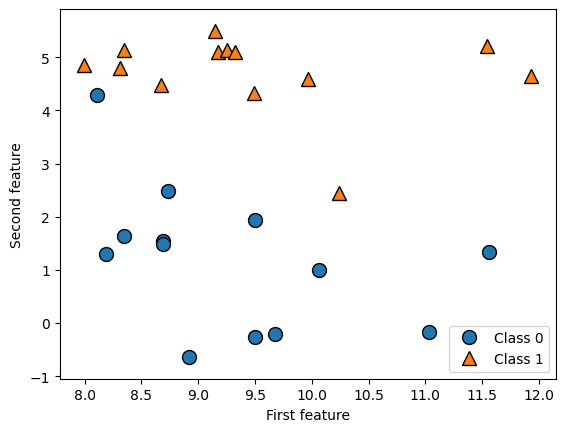

In [2]:
# generate dataset
import mglearn
import matplotlib.pyplot as plt
X, y = mglearn.datasets.make_forge()
# plot dataset
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.legend(["Class 0", "Class 1"], loc=4)
plt.xlabel("First feature")
plt.ylabel("Second feature")
print("X.shape: {}".format(X.shape))

Text(0, 0.5, 'Target')

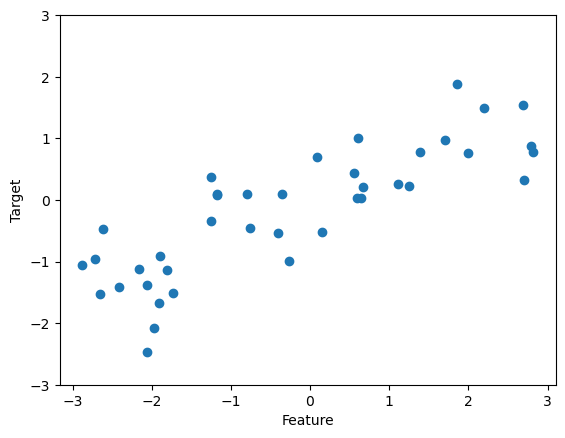

In [3]:
X, y = mglearn.datasets.make_wave(n_samples=40)
plt.plot(X, y, 'o')
plt.ylim(-3, 3)
plt.xlabel("Feature")
plt.ylabel("Target")

In [4]:
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer()
print("cancer.keys(): \n{}".format(cancer.keys()))

cancer.keys(): 
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [5]:
print("Shape of cancer data: {}".format(cancer.data.shape))

Shape of cancer data: (569, 30)


In [7]:
import numpy as np
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
print("Sample counts per class:\n{}".format(
    {n: v for n, v in zip(cancer.target_names, np.bincount(cancer.target))}))

Sample counts per class:
{np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


In [8]:
print("Feature names:\n{}".format(cancer.feature_names))

Feature names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [10]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()

print("Data shape: {}".format(housing.data.shape))
print("Target shape: {}".format(housing.target.shape))
print("Feature names:\n{}".format(housing.feature_names))

Data shape: (20640, 8)
Target shape: (20640,)
Feature names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


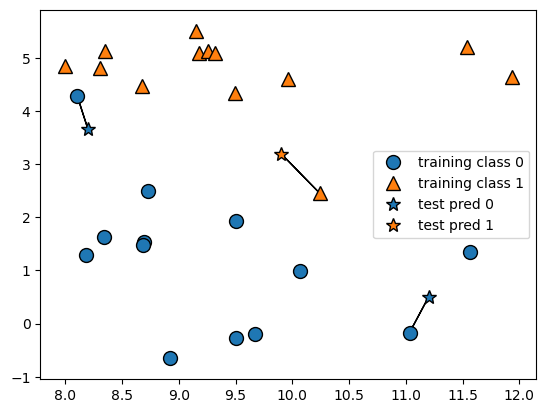

In [11]:
mglearn.plots.plot_knn_classification(n_neighbors=1)

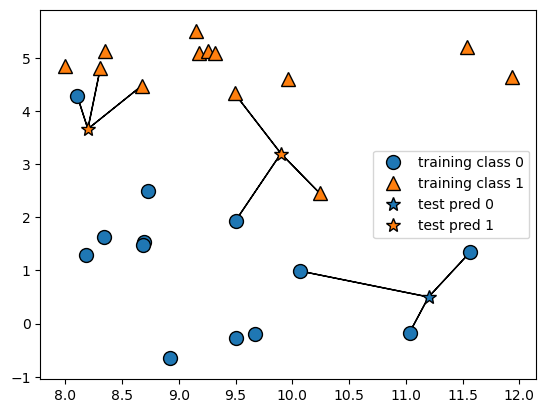

In [12]:
mglearn.plots.plot_knn_classification(n_neighbors=3)

In [13]:
from sklearn.model_selection import train_test_split
X, y = mglearn.datasets.make_forge()
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)
print("Test set predictions: {}".format(clf.predict(X_test)))

Test set predictions: [1 0 1 0 1 0 0]


In [14]:
print("Test set accuracy: {:.2f}".format(clf.score(X_test, y_test)))

Test set accuracy: 0.86


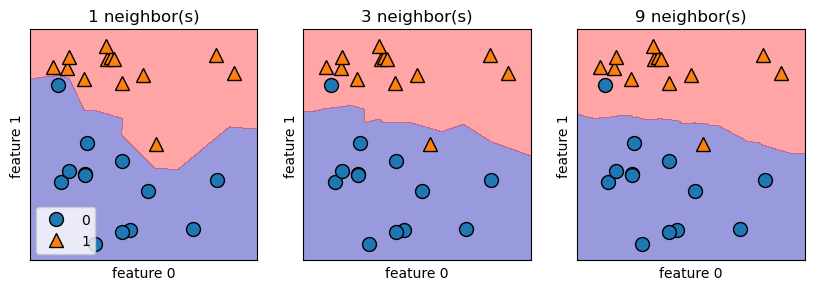

In [18]:
import matplotlib.pyplot as plt
import mglearn
from sklearn.neighbors import KNeighborsClassifier

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for n_neighbors, ax in zip([1, 3, 9], axes):
    # Fit the KNN classifier
    clf = KNeighborsClassifier(n_neighbors=n_neighbors).fit(X, y)

    # Plot the decision boundary
    mglearn.plots.plot_2d_separator(
        clf, X, fill=True, eps=0.5, ax=ax, alpha=.4
    )

    # Plot the data points
    mglearn.discrete_scatter(
        X[:, 0], X[:, 1], y, ax=ax
    )

    ax.set_title("{} neighbor(s)".format(n_neighbors))
    ax.set_xlabel("feature 0")
    ax.set_ylabel("feature 1")

axes[0].legend(loc=3)

plt.show()

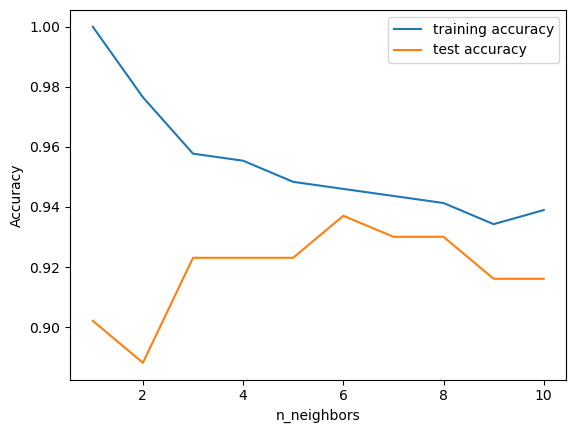

In [20]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# Load the breast cancer dataset
cancer = load_breast_cancer()

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data,
    cancer.target,
    stratify=cancer.target,
    random_state=66
)

# Lists to store accuracy
training_accuracy = []
test_accuracy = []

# Try n_neighbors from 1 to 10
neighbors_settings = range(1, 11)

for n_neighbors in neighbors_settings:

    # Build the model
    clf = KNeighborsClassifier(n_neighbors=n_neighbors)

    # Train the model
    clf.fit(X_train, y_train)

    # Record training set accuracy
    training_accuracy.append(clf.score(X_train, y_train))

    # Record test set accuracy
    test_accuracy.append(clf.score(X_test, y_test))

# Plot the results
plt.plot(neighbors_settings, training_accuracy, label="training accuracy")
plt.plot(neighbors_settings, test_accuracy, label="test accuracy")

plt.ylabel("Accuracy")
plt.xlabel("n_neighbors")
plt.legend()

plt.show()

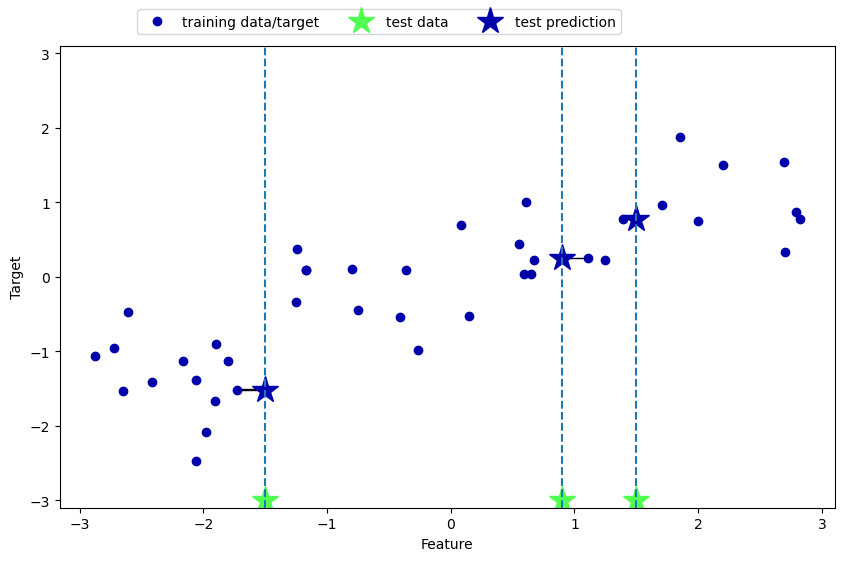

In [21]:
mglearn.plots.plot_knn_regression(n_neighbors=1)

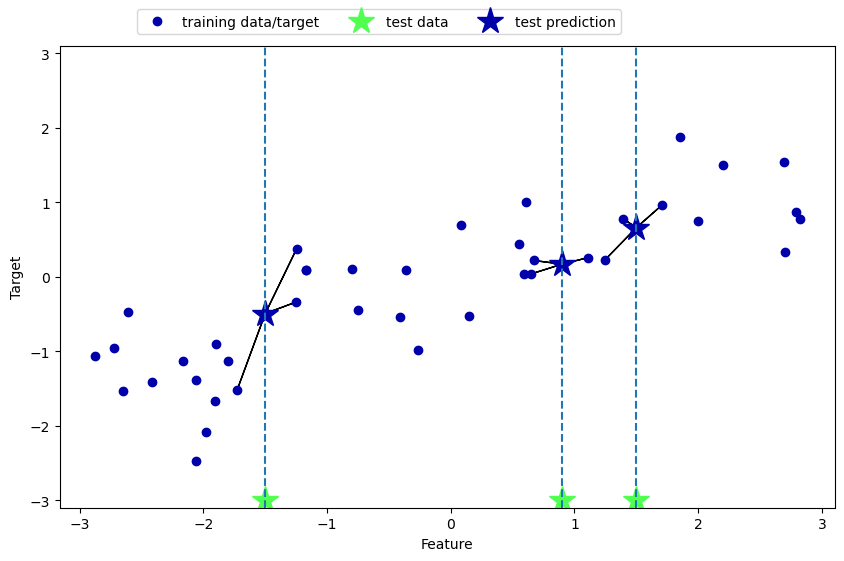

In [22]:
mglearn.plots.plot_knn_regression(n_neighbors=3)

In [23]:
from sklearn.neighbors import KNeighborsRegressor
X, y = mglearn.datasets.make_wave(n_samples=40)
# split the wave dataset into a training and a test set
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
# instantiate the model and set the number of neighbors to consider to 3
reg = KNeighborsRegressor(n_neighbors=3)
# fit the model using the training data and training targets
reg.fit(X_train, y_train)

print("Test set predictions:\n{}".format(reg.predict(X_test)))

Test set predictions:
[-0.05396539  0.35686046  1.13671923 -1.89415682 -1.13881398 -1.63113382
  0.35686046  0.91241374 -0.44680446 -1.13881398]


In [24]:
print("Test set R^2: {:.2f}".format(reg.score(X_test, y_test)))

Test set R^2: 0.83


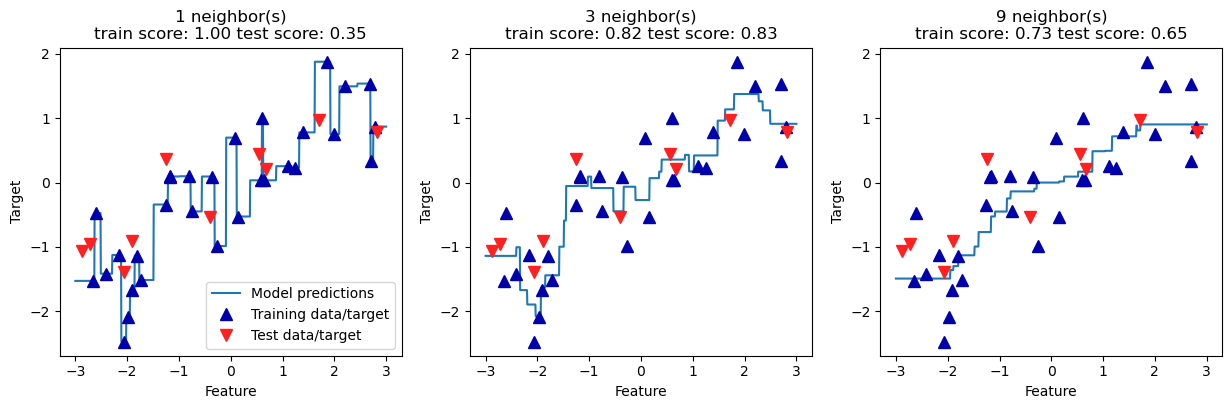

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import mglearn

from sklearn.neighbors import KNeighborsRegressor

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Create 1,000 data points, evenly spaced between -3 and 3
line = np.linspace(-3, 3, 1000).reshape(-1, 1)

for n_neighbors, ax in zip([1, 3, 9], axes):

    # Make predictions using 1, 3, or 9 neighbors
    reg = KNeighborsRegressor(n_neighbors=n_neighbors)

    # Train the model
    reg.fit(X_train, y_train)

    # Plot model predictions
    ax.plot(line, reg.predict(line))

    # Plot training data
    ax.plot(
        X_train, y_train,
        '^',
        c=mglearn.cm2(0),
        markersize=8
    )

    # Plot test data
    ax.plot(
        X_test, y_test,
        'v',
        c=mglearn.cm2(1),
        markersize=8
    )

    # Display scores
    ax.set_title(
        "{} neighbor(s)\ntrain score: {:.2f} test score: {:.2f}".format(
            n_neighbors,
            reg.score(X_train, y_train),
            reg.score(X_test, y_test)
        )
    )

    ax.set_xlabel("Feature")
    ax.set_ylabel("Target")

axes[0].legend(
    ["Model predictions", "Training data/target", "Test data/target"],
    loc="best"
)

plt.show()

w[0]: 0.393906  b: -0.031804


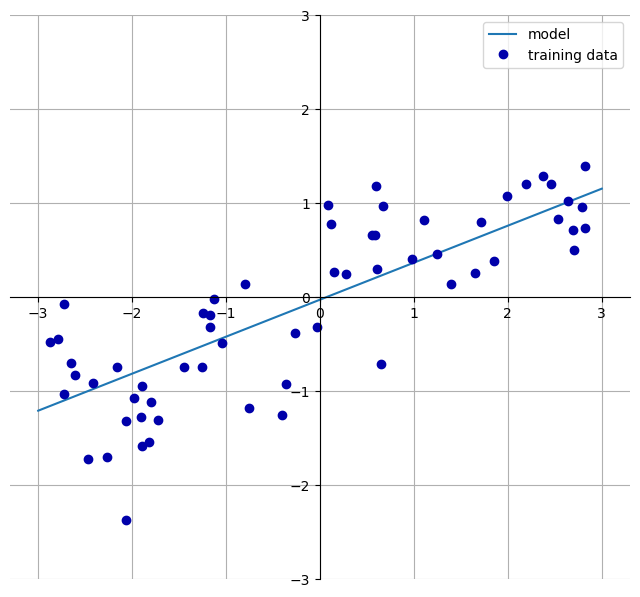

In [29]:
mglearn.plots.plot_linear_regression_wave()

In [30]:
from sklearn.linear_model import LinearRegression
X, y = mglearn.datasets.make_wave(n_samples=60)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
lr = LinearRegression().fit(X_train, y_train)
print("lr.coef_: {}".format(lr.coef_))
print("lr.intercept_: {}".format(lr.intercept_))
print("Training set score: {:.2f}".format(lr.score(X_train, y_train)))
print("Test set score: {:.2f}".format(lr.score(X_test, y_test)))

lr.coef_: [0.39390555]
lr.intercept_: -0.03180434302675966
Training set score: 0.67
Test set score: 0.66


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import mglearn
X, y = mglearn.datasets.load_extended_boston()
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
lr = LinearRegression().fit(X_train, y_train)
print("Training set score: {:.2f}".format(lr.score(X_train, y_train)))
print("Test set score: {:.2f}".format(lr.score(X_test, y_test)))

Training set score: 0.95
Test set score: 0.61


In [34]:
from sklearn.linear_model import Ridge
ridge = Ridge().fit(X_train, y_train)
print("Training set score: {:.2f}".format(ridge.score(X_train, y_train)))
print("Test set score: {:.2f}".format(ridge.score(X_test, y_test)))

Training set score: 0.89
Test set score: 0.75


In [35]:
ridge10 = Ridge(alpha=10).fit(X_train, y_train)
print("Training set score: {:.2f}".format(ridge10.score(X_train, y_train)))
print("Test set score: {:.2f}".format(ridge10.score(X_test, y_test)))
ridge01 = Ridge(alpha=0.1).fit(X_train, y_train)
print("Training set score: {:.2f}".format(ridge01.score(X_train, y_train)))
print("Test set score: {:.2f}".format(ridge01.score(X_test, y_test)))

Training set score: 0.79
Test set score: 0.64
Training set score: 0.93
Test set score: 0.77


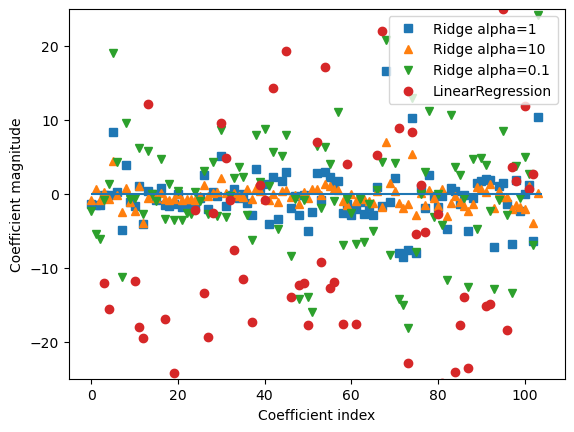

In [36]:
plt.plot(ridge.coef_, 's', label="Ridge alpha=1")
plt.plot(ridge10.coef_,
'^'
, label="Ridge alpha=10")
plt.plot(ridge01.coef_, 'v', label="Ridge alpha=0.1")
plt.plot(lr.coef_, 'o', label="LinearRegression")
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")
plt.hlines(0, 0, len(lr.coef_))
plt.ylim(-25, 25)
plt.legend()

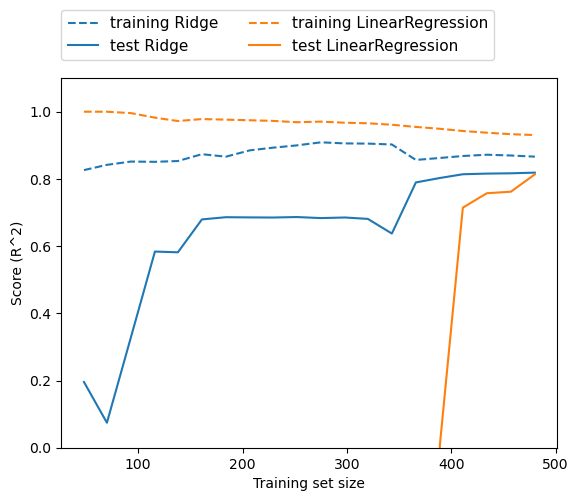

In [39]:
mglearn.plots.plot_ridge_n_samples()

In [40]:
from sklearn.linear_model import Lasso
lasso = Lasso().fit(X_train, y_train)
print("Training set score: {:.2f}".format(lasso.score(X_train, y_train)))
print("Test set score: {:.2f}".format(lasso.score(X_test, y_test)))
print("Number of features used: {}".format(np.sum(lasso.coef_ != 0)))

Training set score: 0.29
Test set score: 0.21
Number of features used: 4


In [41]:
# we increase the default setting of "max_iter",
# otherwise the model would warn us that we should increase max_iter.
lasso001 = Lasso(alpha=0.01, max_iter=100000).fit(X_train, y_train)
print("Training set score: {:.2f}".format(lasso001.score(X_train, y_train)))
print("Test set score: {:.2f}".format(lasso001.score(X_test, y_test)))
print("Number of features used: {}".format(np.sum(lasso001.coef_ != 0)))

Training set score: 0.90
Test set score: 0.77
Number of features used: 33


In [42]:
lasso00001 = Lasso(alpha=0.0001, max_iter=100000).fit(X_train, y_train)
print("Training set score: {:.2f}".format(lasso00001.score(X_train, y_train)))
print("Test set score: {:.2f}".format(lasso00001.score(X_test, y_test)))
print("Number of features used: {}".format(np.sum(lasso00001.coef_ != 0)))

Training set score: 0.95
Test set score: 0.64
Number of features used: 96


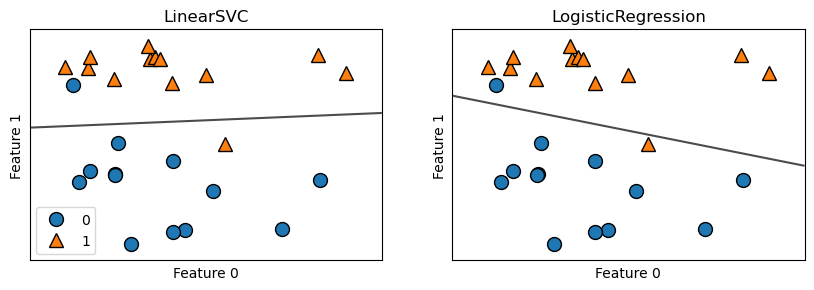

In [45]:
import matplotlib.pyplot as plt
import mglearn

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Create forge dataset
X, y = mglearn.datasets.make_forge()

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

# Compare LinearSVC and LogisticRegression
for model, ax in zip(
    [LinearSVC(max_iter=10000), LogisticRegression()],
    axes
):

    # Train the model
    clf = model.fit(X, y)

    # Plot decision boundary
    mglearn.plots.plot_2d_separator(
        clf,
        X,
        fill=False,
        eps=0.5,
        ax=ax,
        alpha=.7
    )

    # Plot data points
    mglearn.discrete_scatter(
        X[:, 0],
        X[:, 1],
        y,
        ax=ax
    )

    # Set title and labels
    ax.set_title("{}".format(clf.__class__.__name__))
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")

# Add legend
axes[0].legend()

plt.show()

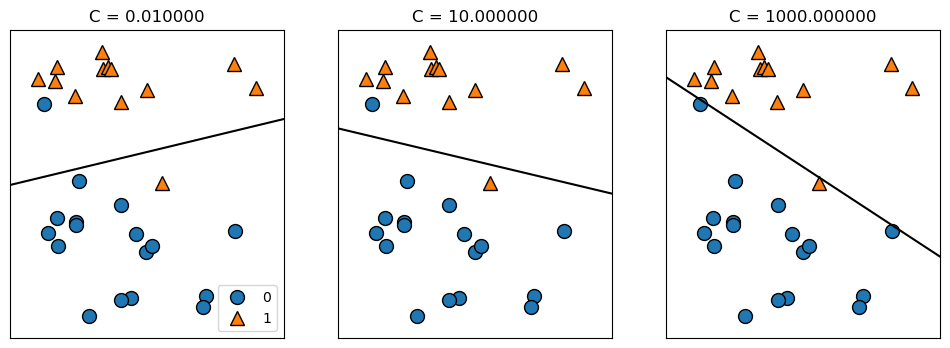

In [46]:
mglearn.plots.plot_linear_svc_regularization()

In [49]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Load the breast cancer dataset
cancer = load_breast_cancer()

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data,
    cancer.target,
    stratify=cancer.target,
    random_state=42
)

# Create and train Logistic Regression model
logreg = LogisticRegression(max_iter=10000).fit(X_train, y_train)

# Print training accuracy
print("Training set score: {:.3f}".format(
    logreg.score(X_train, y_train)
))

# Print test accuracy
print("Test set score: {:.3f}".format(
    logreg.score(X_test, y_test)
))

Training set score: 0.958
Test set score: 0.958


In [52]:
logreg100 = LogisticRegression(C=100, max_iter=10000).fit(X_train, y_train)

print("Training set score: {:.3f}".format(
    logreg100.score(X_train, y_train)
))

print("Test set score: {:.3f}".format(
    logreg100.score(X_test, y_test)
))

Training set score: 0.981
Test set score: 0.965


In [54]:
logreg001 = LogisticRegression(C=0.01, max_iter=10000).fit(
    X_train, y_train
)

print("Training set score: {:.3f}".format(
    logreg001.score(X_train, y_train)
))

print("Test set score: {:.3f}".format(
    logreg001.score(X_test, y_test)
))

Training set score: 0.953
Test set score: 0.951


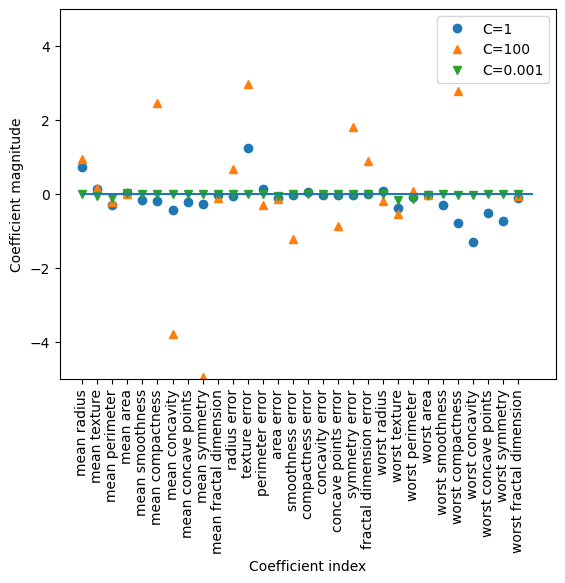

In [55]:
plt.plot(logreg.coef_.T, 'o', label="C=1")
plt.plot(logreg100.coef_.T,
'^'
, label="C=100")
plt.plot(logreg001.coef_.T, 'v', label="C=0.001")
plt.xticks(range(cancer.data.shape[1]), cancer.feature_names, rotation=90)
plt.hlines(0, 0, cancer.data.shape[1])
plt.ylim(-5, 5)
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")
plt.legend()

Training accuracy of l1 logreg with C=0.001: 0.91
Test accuracy of l1 logreg with C=0.001: 0.92
Training accuracy of l1 logreg with C=1.000: 0.96
Test accuracy of l1 logreg with C=1.000: 0.96
Training accuracy of l1 logreg with C=100.000: 0.99
Test accuracy of l1 logreg with C=100.000: 0.98


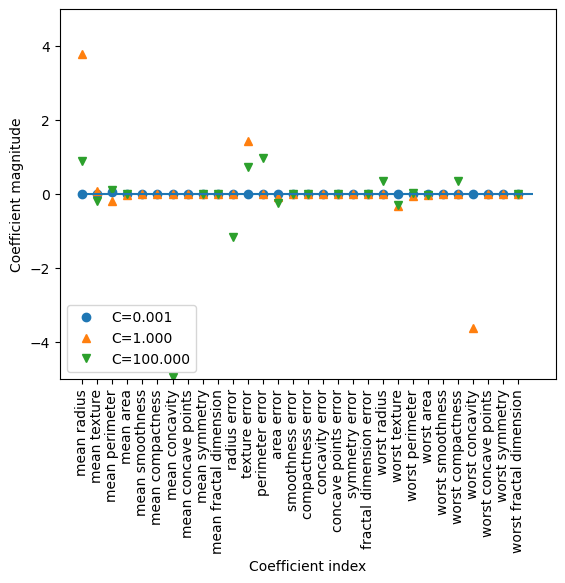

In [57]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

for C, marker in zip([0.001, 1, 100], ['o', '^', 'v']):

    lr_l1 = LogisticRegression(
        C=C,
        penalty="l1",
        solver="liblinear",
        max_iter=10000
    ).fit(X_train, y_train)

    print(
        "Training accuracy of l1 logreg with C={:.3f}: {:.2f}".format(
            C, lr_l1.score(X_train, y_train)
        )
    )

    print(
        "Test accuracy of l1 logreg with C={:.3f}: {:.2f}".format(
            C, lr_l1.score(X_test, y_test)
        )
    )

    plt.plot(
        lr_l1.coef_.T,
        marker,
        label="C={:.3f}".format(C)
    )

plt.xticks(
    range(cancer.data.shape[1]),
    cancer.feature_names,
    rotation=90
)

plt.hlines(0, 0, cancer.data.shape[1])
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")
plt.ylim(-5, 5)
plt.legend(loc=3)

plt.show()

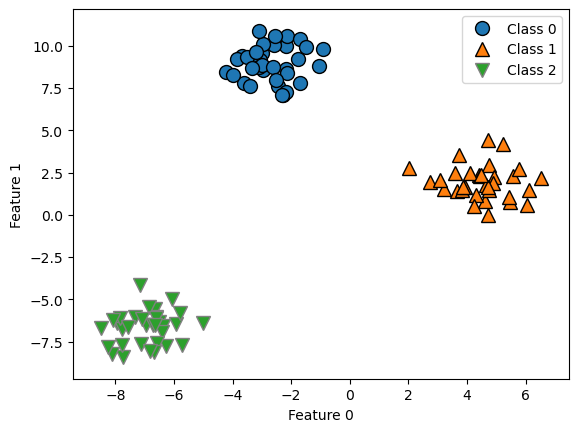

In [58]:
from sklearn.datasets import make_blobs
X, y = make_blobs(random_state=42)
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.legend(["Class 0", "Class 1", "Class 2"])

In [59]:
linear_svm = LinearSVC().fit(X, y)
print("Coefficient shape: ", linear_svm.coef_.shape)
print("Intercept shape: ", linear_svm.intercept_.shape)

Coefficient shape:  (3, 2)
Intercept shape:  (3,)


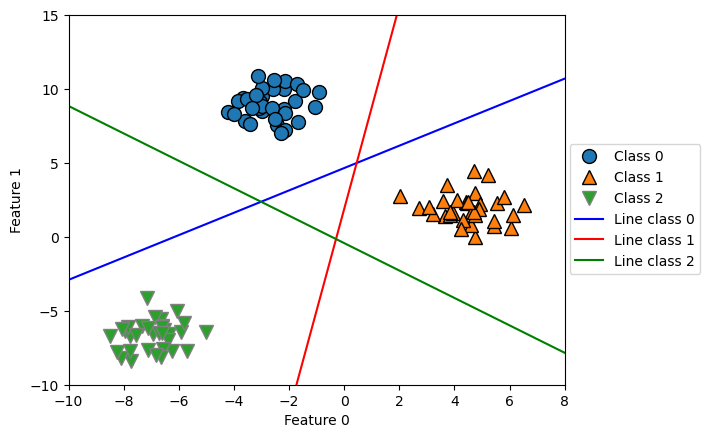

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import mglearn

# Plot the data points
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)

# Create x-values
line = np.linspace(-15, 15)

# Plot the three decision boundary lines
for coef, intercept, color in zip(
    linear_svm.coef_,
    linear_svm.intercept_,
    ['b', 'r', 'g']
):
    plt.plot(
        line,
        -(line * coef[0] + intercept) / coef[1],
        c=color
    )

plt.ylim(-10, 15)
plt.xlim(-10, 8)

plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

plt.legend([
    'Class 0',
    'Class 1',
    'Class 2',
    'Line class 0',
    'Line class 1',
    'Line class 2'
], loc=(1.01, 0.3))

plt.show()

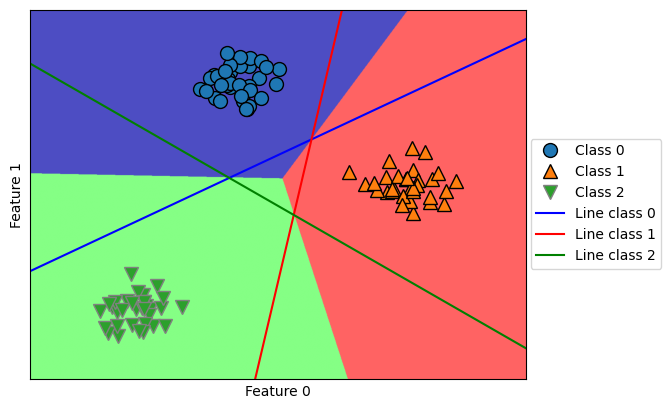

In [63]:
import numpy as np
import matplotlib.pyplot as plt
import mglearn

mglearn.plots.plot_2d_classification(
    linear_svm, X, fill=True, alpha=.7
)

mglearn.discrete_scatter(
    X[:, 0], X[:, 1], y
)

line = np.linspace(-15, 15)

for coef, intercept, color in zip(
    linear_svm.coef_,
    linear_svm.intercept_,
    ['b', 'r', 'g']
):
    plt.plot(
        line,
        -(line * coef[0] + intercept) / coef[1],
        c=color
    )

plt.legend([
    'Class 0',
    'Class 1',
    'Class 2',
    'Line class 0',
    'Line class 1',
    'Line class 2'
], loc=(1.01, 0.3))

plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

plt.show()

In [65]:
# instantiate model and fit it in one line
##logreg = LogisticRegression().fit(X_train, y_train)
#logreg = LogisticRegression()
#y_pred = logreg.fit(X_train, y_train).predict(X_test)
#Method Chaining
#The fit method of all scikit-learn models returns self. This allows you to write
#code like the following, which we’ve already used extensively in this chapter:
#In[51]:
# instantiate model and fit it in one line
#logreg = LogisticRegression().fit(X_train, y_train)
#Here, we used the return value of fit (which is self) to assign the trained model to
#the variable logreg. This concatenation of method calls (here __init__ and then fit)
#is known as method chaining. Another common application of method chaining in
#scikit-learn is to fit and predict in one line:
#In[52]:
#logreg = LogisticRegression()
#y_pred = logreg.fit(X_train, y_train).predict(X_test)
#Finally, you can even do model instantiation, fitting, and predicting in one line:
#In[53]:
#y_pred = LogisticRegression().fit(X_train, y_train).predict(X_test)
#This very short variant is not ideal, though. A lot is happening in a single line, which
#might make the code hard to read. Additionally, the fitted logistic regression model
#isn’t stored in any variable, so we can’t inspect it or use it to predict on any other data.\\\

In [ ]:
import numpy as np

X = np.array([
    [0, 1, 0, 1],
    [1, 0, 1, 1],
    [0, 0, 0, 1],
    [1, 0, 1, 0]
])

y = np.array([0, 1, 0, 1])

counts = {}

for label in np.unique(y):
    # Iterate over each class
    # Count (sum) entries of 1 per feature
    counts[label] = X[y == label].sum(axis=0)

print("Feature counts:\n{}".format(counts))

In [4]:
import subprocess
print(subprocess.run(["dot", "-V"], capture_output=True, text=True).stderr)

dot - graphviz version 9.0.0 (0)



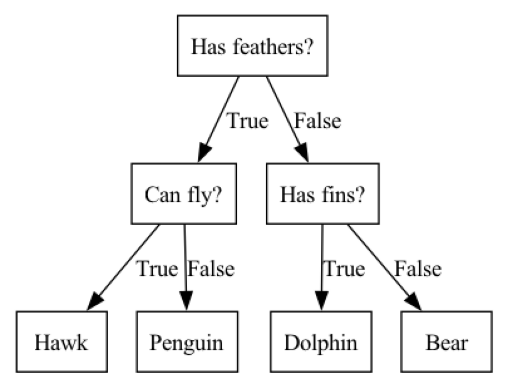

In [5]:
mglearn.plots.plot_animal_tree()

In [7]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Load breast cancer dataset
cancer = load_breast_cancer()

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data,
    cancer.target,
    stratify=cancer.target,
    random_state=42
)

# Create and train Decision Tree
tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)

# Check accuracy
print("Accuracy on training set: {:.3f}".format(
    tree.score(X_train, y_train)
))

print("Accuracy on test set: {:.3f}".format(
    tree.score(X_test, y_test)
))

Accuracy on training set: 1.000
Accuracy on test set: 0.937


In [8]:
tree = DecisionTreeClassifier(max_depth=4, random_state=0)
tree.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(tree.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(tree.score(X_test, y_test)))

Accuracy on training set: 0.988
Accuracy on test set: 0.951


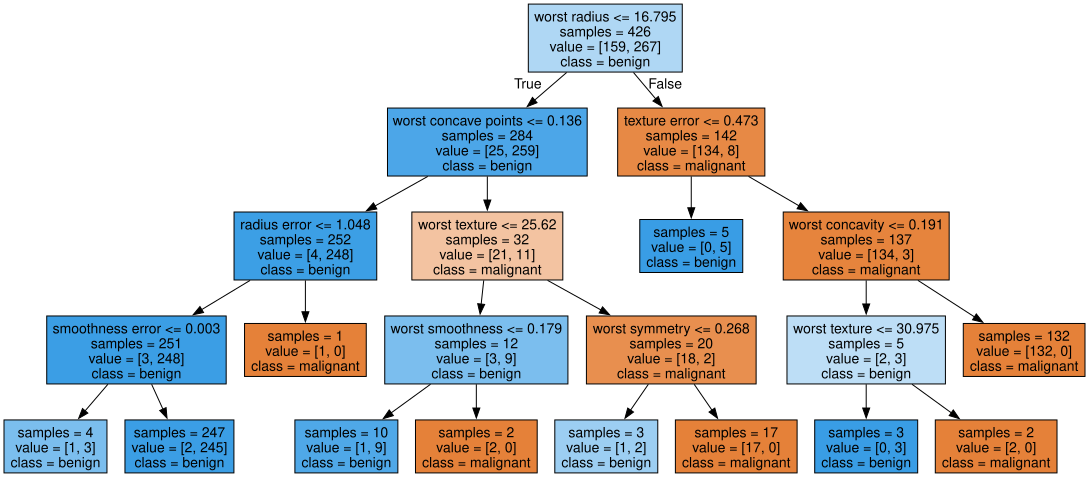

In [11]:
from sklearn.tree import export_graphviz
import graphviz

# Export the decision tree to a .dot file
export_graphviz(
    tree,
    out_file="tree.dot",
    class_names=["malignant", "benign"],
    feature_names=cancer.feature_names,
    impurity=False,
    filled=True
)

# Read the .dot file
with open("tree.dot") as f:
    dot_graph = f.read()

# Display the tree
graphviz.Source(dot_graph)

In [12]:
print("Feature importances:\n{}".format(tree.feature_importances_))

Feature importances:
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.01019737 0.04839825
 0.         0.         0.0024156  0.         0.         0.
 0.         0.         0.72682851 0.0458159  0.         0.
 0.0141577  0.         0.018188   0.1221132  0.01188548 0.        ]


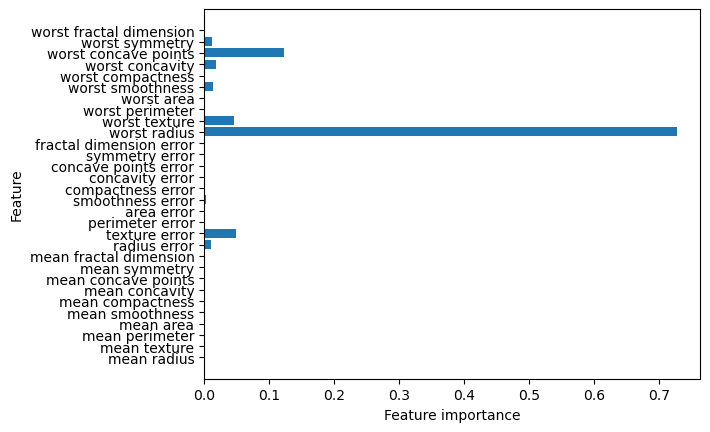

In [15]:
import numpy as np
import matplotlib.pyplot as plt
def plot_feature_importances_cancer(model):
    n_features = cancer.data.shape[1]

    plt.barh(
        range(n_features),
        model.feature_importances_,
        align='center'
    )

    plt.yticks(
        np.arange(n_features),
        cancer.feature_names
    )

    plt.xlabel("Feature importance")
    plt.ylabel("Feature")


plot_feature_importances_cancer(tree)

Feature importances: [0. 1.]


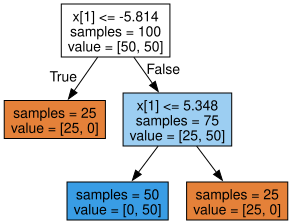

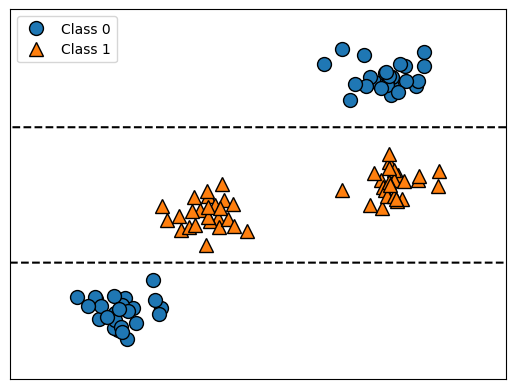

In [16]:
tree = mglearn.plots.plot_tree_not_monotone()
display(tree)

In [2]:
import os

!find ~ -name "ram_price.csv" 2>/dev/null

In [8]:
import os

print(os.getcwd())

/Users/beka/Python Projects


In [9]:
print(os.listdir())

['Chapter2.ipynb', '.DS_Store', 'cache', 'mytree.dot', 'tmp.png', 'chapter1.ipynb', '.ipynb_checkpoints', 'tmp', 'tree.dot']


In [10]:
print(os.path.exists("data/ram_price.csv"))

False


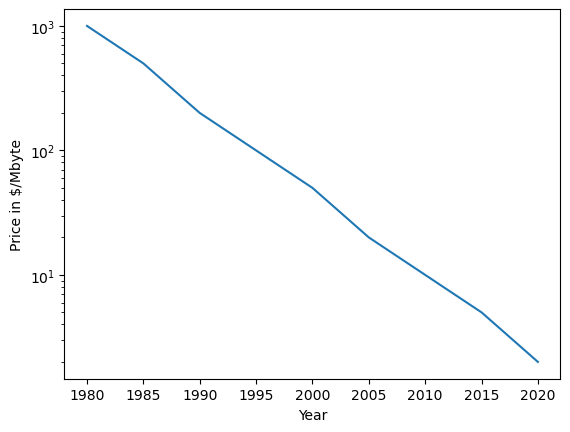

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

ram_prices = pd.DataFrame({
    "date": [1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020],
    "price": [1000, 500, 200, 100, 50, 20, 10, 5, 2]
})

plt.semilogy(ram_prices.date, ram_prices.price)
plt.xlabel("Year")
plt.ylabel("Price in $/Mbyte")
plt.show()

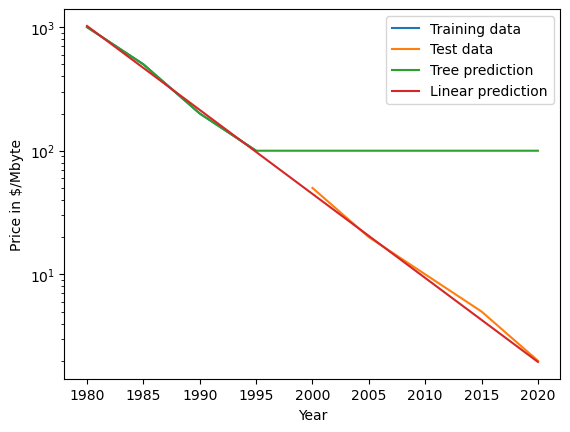

In [14]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

# Use historical data to forecast prices after the year 2000
data_train = ram_prices[ram_prices.date < 2000]
data_test = ram_prices[ram_prices.date >= 2000]

# Predict prices based on date
X_train = data_train.date.to_numpy()[:, np.newaxis]

# Use a log-transform to get a simpler relationship
y_train = np.log(data_train.price)

# Train models
tree = DecisionTreeRegressor().fit(X_train, y_train)
linear_reg = LinearRegression().fit(X_train, y_train)

# Predict on all data
X_all = ram_prices.date.to_numpy()[:, np.newaxis]

pred_tree = tree.predict(X_all)
pred_lr = linear_reg.predict(X_all)

# Undo log-transform
price_tree = np.exp(pred_tree)
price_lr = np.exp(pred_lr)

# Plot
plt.semilogy(data_train.date, data_train.price, label="Training data")
plt.semilogy(data_test.date, data_test.price, label="Test data")
plt.semilogy(ram_prices.date, price_tree, label="Tree prediction")
plt.semilogy(ram_prices.date, price_lr, label="Linear prediction")

plt.legend()
plt.xlabel("Year")
plt.ylabel("Price in $/Mbyte")
plt.show()

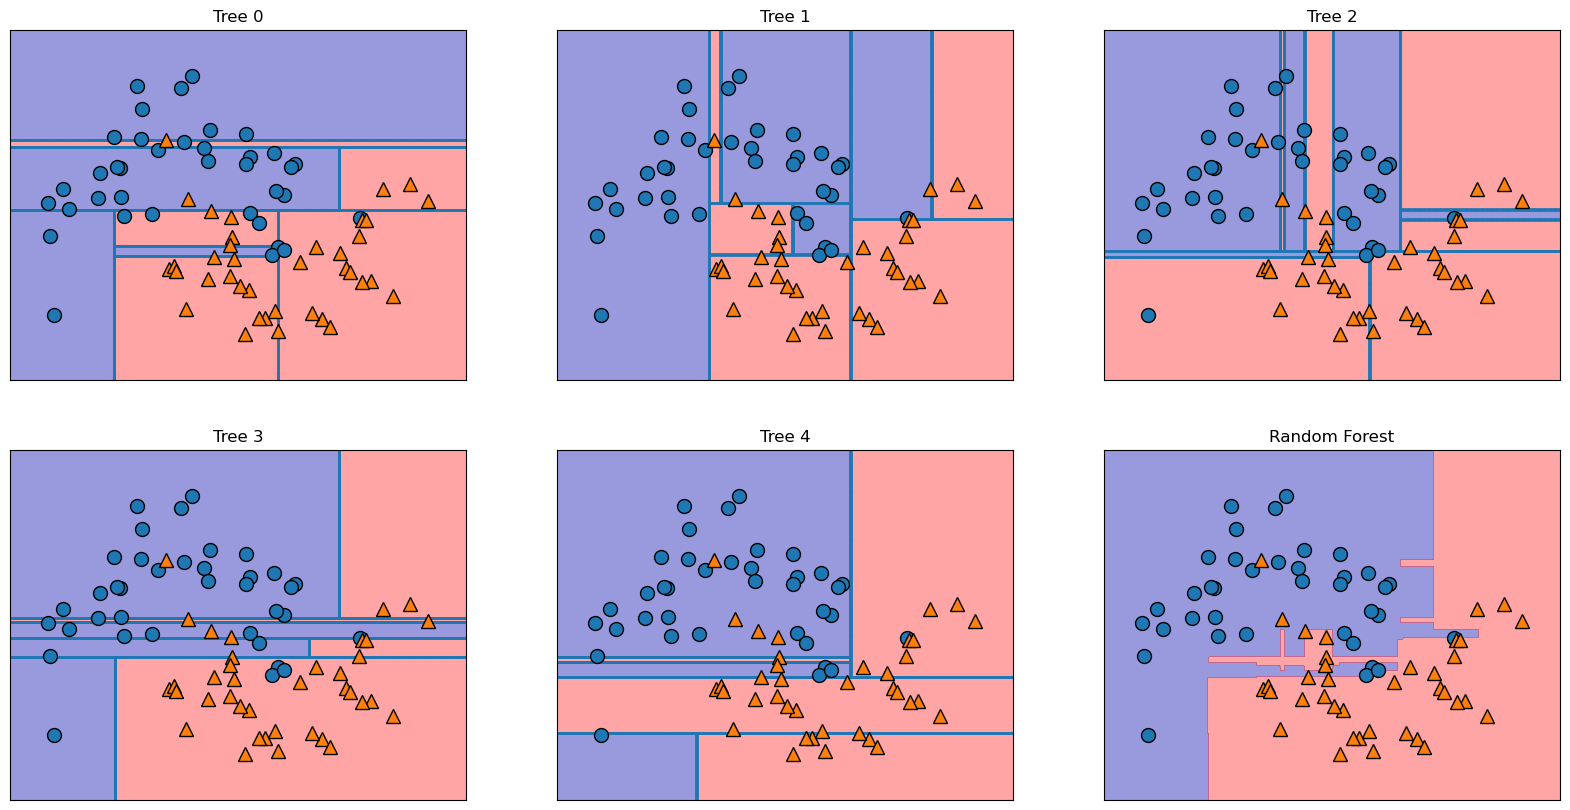

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import mglearn

from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Create the dataset
X, y = make_moons(
    n_samples=100,
    noise=0.25,
    random_state=3
)

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    stratify=y,
    random_state=42
)

# Create and train Random Forest
forest = RandomForestClassifier(
    n_estimators=5,
    random_state=2
)

forest.fit(X_train, y_train)

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

# Show each decision tree
for i, (ax, tree) in enumerate(
    zip(axes.ravel(), forest.estimators_)
):
    ax.set_title("Tree {}".format(i))
    mglearn.plots.plot_tree_partition(
        X_train,
        y_train,
        tree,
        ax=ax
    )

# Show Random Forest decision boundary
mglearn.plots.plot_2d_separator(
    forest,
    X_train,
    fill=True,
    ax=axes[-1, -1],
    alpha=.4
)

axes[-1, -1].set_title("Random Forest")

# Show training data
mglearn.discrete_scatter(
    X_train[:, 0],
    X_train[:, 1],
    y_train,
    ax=axes[-1, -1]
)

plt.show()

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Load breast cancer dataset
cancer = load_breast_cancer()

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data,
    cancer.target,
    random_state=0
)

# Create Random Forest model
forest = RandomForestClassifier(
    n_estimators=100,
    random_state=0
)

# Train the model
forest.fit(X_train, y_train)

# Check accuracy
print("Accuracy on training set: {:.3f}".format(
    forest.score(X_train, y_train)
))

print("Accuracy on test set: {:.3f}".format(
    forest.score(X_test, y_test)
))

Accuracy on training set: 1.000
Accuracy on test set: 0.972


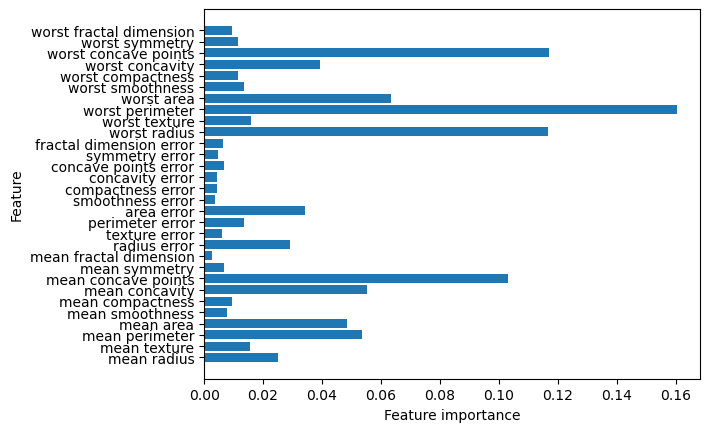

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def plot_feature_importances_cancer(model):
    n_features = cancer.data.shape[1]

    plt.barh(
        range(n_features),
        model.feature_importances_,
        align='center'
    )

    plt.yticks(
        np.arange(n_features),
        cancer.feature_names
    )

    plt.xlabel("Feature importance")
    plt.ylabel("Feature")

    plt.show()

plot_feature_importances_cancer(forest)

In [21]:
from sklearn.ensemble import GradientBoostingClassifier
X_train, X_test, y_train, y_test = train_test_split(
cancer.data, cancer.target, random_state=0)
gbrt = GradientBoostingClassifier(random_state=0)
gbrt.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(gbrt.score(X_test, y_test)))

Accuracy on training set: 1.000
Accuracy on test set: 0.965


In [22]:
gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(gbrt.score(X_test, y_test)))

Accuracy on training set: 0.991
Accuracy on test set: 0.972


In [23]:
gbrt = GradientBoostingClassifier(random_state=0, learning_rate=0.01)
gbrt.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(gbrt.score(X_test, y_test)))

Accuracy on training set: 0.988
Accuracy on test set: 0.958


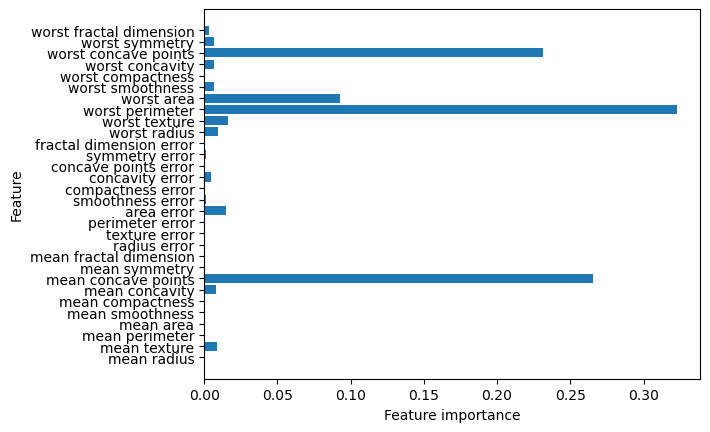

In [24]:
gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)
plot_feature_importances_cancer(gbrt)

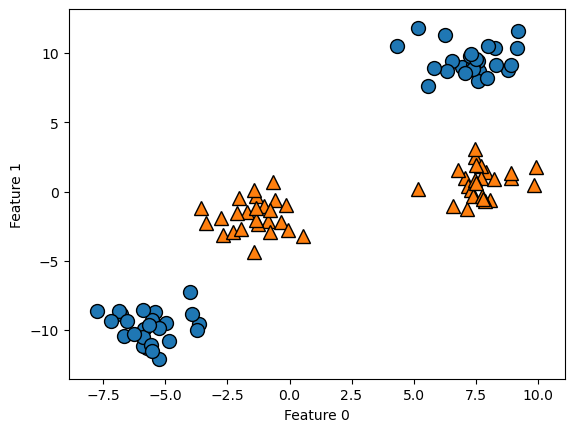

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import mglearn

from sklearn.datasets import make_blobs

# Create 4 clusters
X, y = make_blobs(centers=4, random_state=8)

# Change 4 classes into 2 classes
y = y % 2

# Plot the data
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)

plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.show()

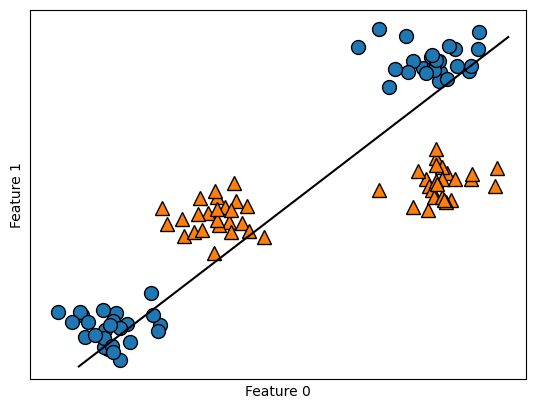

In [28]:
from sklearn.svm import LinearSVC
import matplotlib.pyplot as plt
import mglearn

# Create and train the Linear SVM model
linear_svm = LinearSVC().fit(X, y)

# Draw the decision boundary
mglearn.plots.plot_2d_separator(
    linear_svm, X, eps=0.5, fill=False
)

# Draw the data points
mglearn.discrete_scatter(
    X[:, 0], X[:, 1], y
)

plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.show()

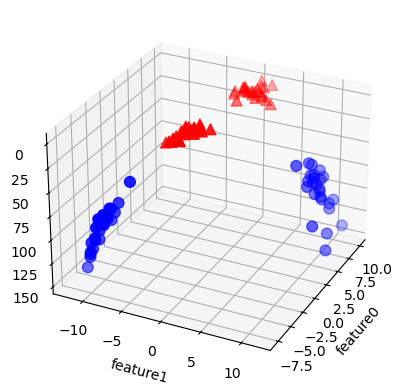

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import mglearn

# Add the squared second feature
X_new = np.hstack([X, X[:, 1:] ** 2])

# Create 3D figure
figure = plt.figure()

# Visualize in 3D
ax = figure.add_subplot(
    111,
    projection="3d",
    elev=-152,
    azim=-26
)

# Class 0
mask = y == 0

ax.scatter(
    X_new[mask, 0],
    X_new[mask, 1],
    X_new[mask, 2],
    c='b',
    s=60
)

# Class 1
ax.scatter(
    X_new[~mask, 0],
    X_new[~mask, 1],
    X_new[~mask, 2],
    c='r',
    marker='^',
    s=60
)

ax.set_xlabel("feature0")
ax.set_ylabel("feature1")
ax.set_zlabel("feature1 ** 2")

plt.show()

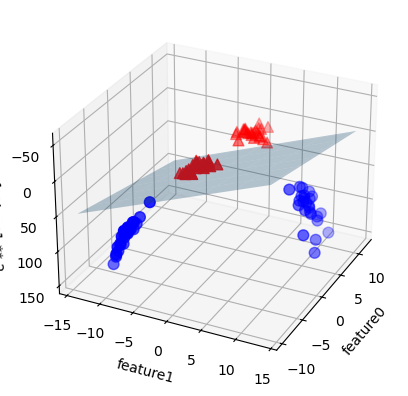

In [32]:
from sklearn.svm import LinearSVC
import numpy as np
import matplotlib.pyplot as plt

# Train Linear SVM using the new 3D data
linear_svm_3d = LinearSVC().fit(X_new, y)

# Get coefficients and intercept
coef = linear_svm_3d.coef_.ravel()
intercept = linear_svm_3d.intercept_[0]

# Create 3D figure
figure = plt.figure()

ax = figure.add_subplot(
    111,
    projection="3d",
    elev=-152,
    azim=-26
)

# Create grid
xx = np.linspace(
    X_new[:, 0].min() - 2,
    X_new[:, 0].max() + 2,
    50
)

yy = np.linspace(
    X_new[:, 1].min() - 2,
    X_new[:, 1].max() + 2,
    50
)

XX, YY = np.meshgrid(xx, yy)

# Calculate decision boundary
ZZ = (
    coef[0] * XX +
    coef[1] * YY +
    intercept
) / -coef[2]

# Plot decision surface
ax.plot_surface(
    XX, YY, ZZ,
    rstride=8,
    cstride=8,
    alpha=0.3
)

# Plot class 0
ax.scatter(
    X_new[mask, 0],
    X_new[mask, 1],
    X_new[mask, 2],
    c='b',
    s=60
)

# Plot class 1
ax.scatter(
    X_new[~mask, 0],
    X_new[~mask, 1],
    X_new[~mask, 2],
    c='r',
    marker='^',
    s=60
)

ax.set_xlabel("feature0")
ax.set_ylabel("feature1")
ax.set_zlabel("feature1 ** 2")

plt.show()

Text(0, 0.5, 'Feature 1')

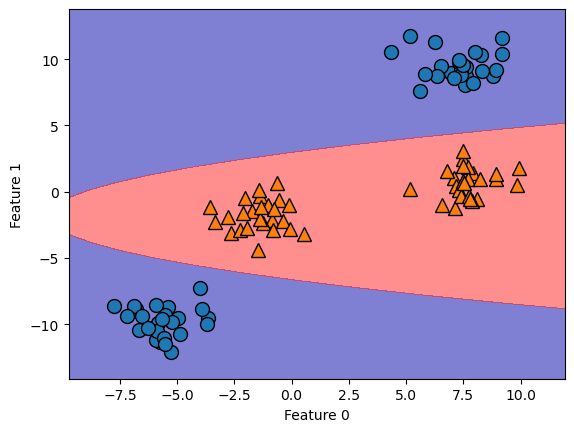

In [33]:
ZZ = YY ** 2
dec = linear_svm_3d.decision_function(np.c_[XX.ravel(), YY.ravel(), ZZ.ravel()])
plt.contourf(XX, YY, dec.reshape(XX.shape), levels=[dec.min(), 0, dec.max()],
cmap=mglearn.cm2, alpha=0.5)
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

Text(0, 0.5, 'Feature 1')

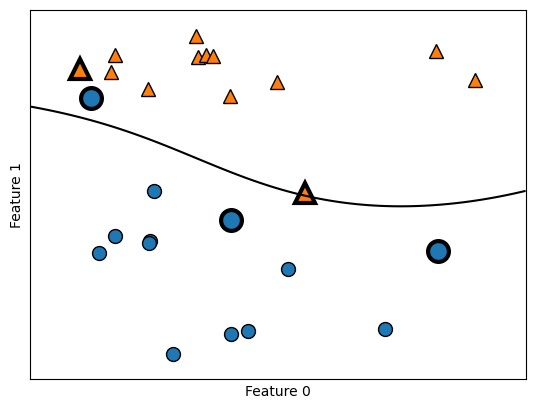

In [34]:
from sklearn.svm import SVC
X, y = mglearn.tools.make_handcrafted_dataset()
svm = SVC(kernel='rbf', C=10, gamma=0.1).fit(X, y)
mglearn.plots.plot_2d_separator(svm, X, eps=.5)
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
# plot support vectors
sv = svm.support_vectors_
# class labels of support vectors are given by the sign of the dual coefficients
sv_labels = svm.dual_coef_.ravel() > 0
mglearn.discrete_scatter(sv[:, 0], sv[:, 1], sv_labels, s=15, markeredgewidth=3)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

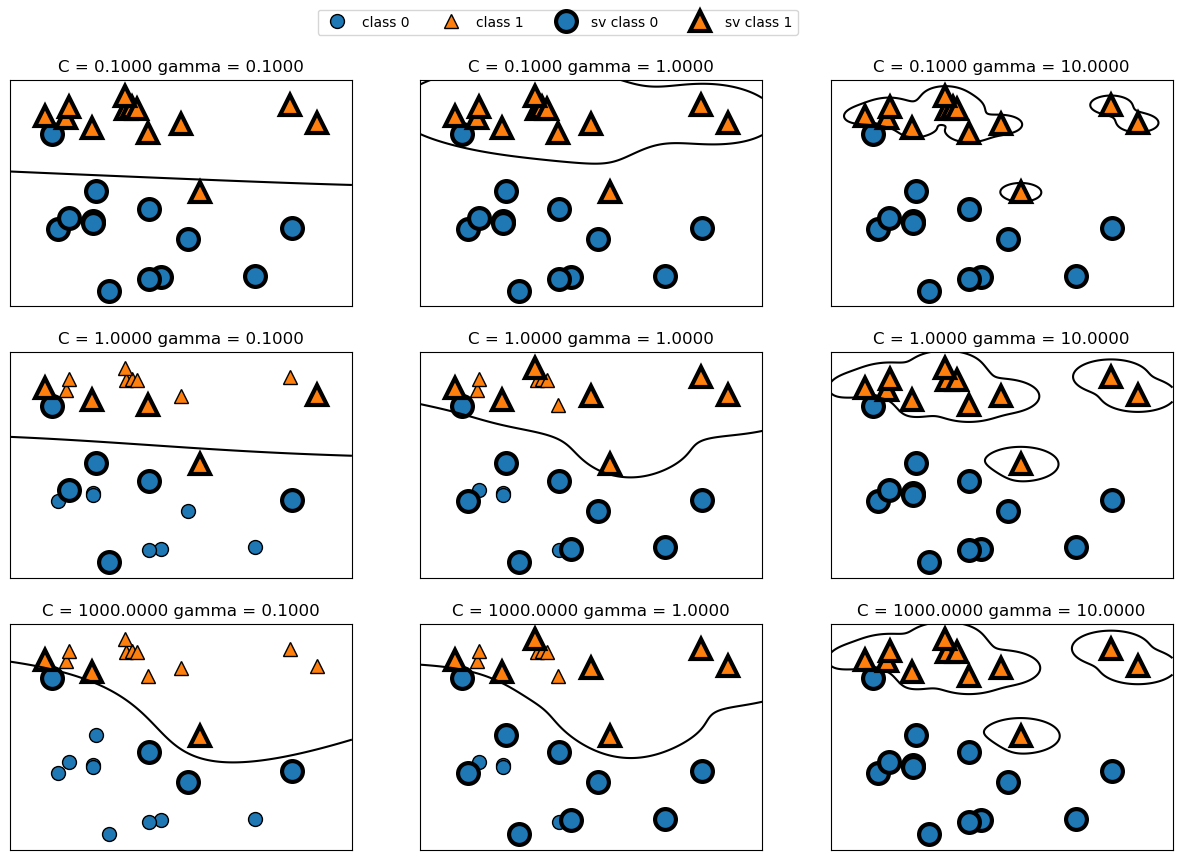

In [36]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, C in zip(axes, [-1, 0, 3]):
    for a, gamma in zip(ax, range(-1, 2)):
        mglearn.plots.plot_svm(
            log_C=C,
            log_gamma=gamma,
            ax=a
        )

axes[0, 0].legend(
    ["class 0", "class 1", "sv class 0", "sv class 1"],
    ncol=4,
    loc=(.9, 1.2)
)

plt.show()

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
cancer.data, cancer.target, random_state=0)
svc = SVC()
svc.fit(X_train, y_train)
print("Accuracy on training set: {:.2f}".format(svc.score(X_train, y_train)))
print("Accuracy on test set: {:.2f}".format(svc.score(X_test, y_test)))

Accuracy on training set: 0.90
Accuracy on test set: 0.94


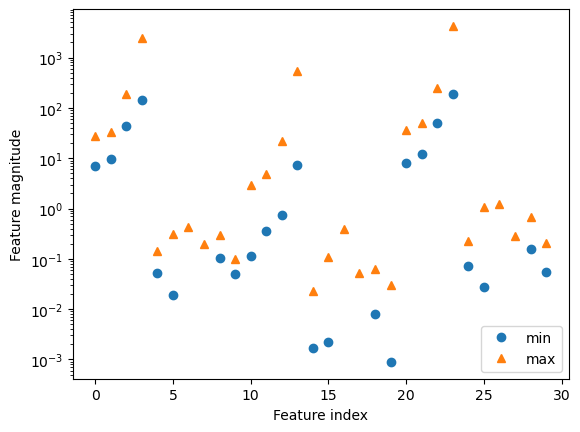

In [38]:
plt.plot(X_train.min(axis=0), 'o', label="min")
plt.plot(X_train.max(axis=0), '^'
, label="max")
plt.legend(loc=4)
plt.xlabel("Feature index")
plt.ylabel("Feature magnitude")
plt.yscale("log")

In [39]:
# compute the minimum value per feature on the training set
min_on_training = X_train.min(axis=0)
# compute the range of each feature (max - min) on the training set
range_on_training = (X_train - min_on_training).max(axis=0)
# subtract the min, and divide by range
# afterward, min=0 and max=1 for each feature
X_train_scaled = (X_train - min_on_training) / range_on_training
print("Minimum for each feature\n{}".format(X_train_scaled.min(axis=0)))
print("Maximum for each feature\n {}".format(X_train_scaled.max(axis=0)))

Minimum for each feature
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
Maximum for each feature
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


In [40]:
# use THE SAME transformation on the test set,
# using min and range of the training set (see Chapter 3 for details)
X_test_scaled = (X_test - min_on_training) / range_on_training
svc = SVC()
svc.fit(X_train_scaled, y_train)
print("Accuracy on training set: {:.3f}".format(
svc.score(X_train_scaled, y_train)))
print("Accuracy on test set: {:.3f}".format(svc.score(X_test_scaled, y_test)))

Accuracy on training set: 0.984
Accuracy on test set: 0.972


In [41]:
svc = SVC(C=1000)
svc.fit(X_train_scaled, y_train)
print("Accuracy on training set: {:.3f}".format(
svc.score(X_train_scaled, y_train)))
print("Accuracy on test set: {:.3f}".format(svc.score(X_test_scaled, y_test)))

Accuracy on training set: 1.000
Accuracy on test set: 0.958


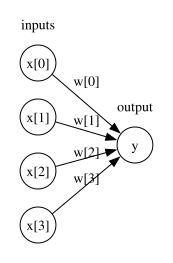

In [42]:
display(mglearn.plots.plot_logistic_regression_graph())

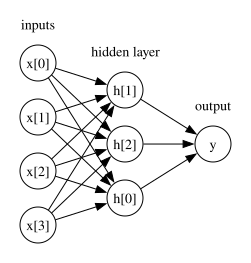

In [43]:
display(mglearn.plots.plot_single_hidden_layer_graph())

Text(0, 0.5, 'relu(x), tanh(x)')

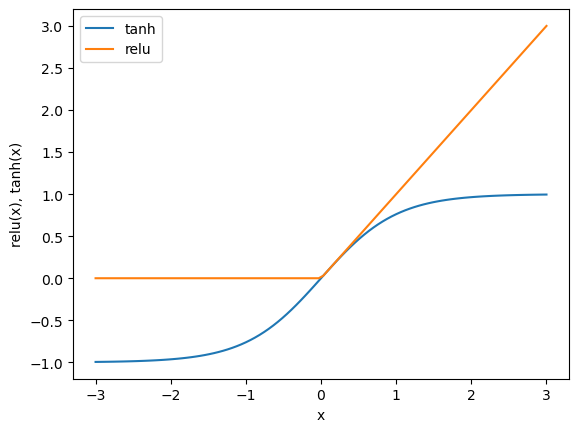

In [44]:
line = np.linspace(-3, 3, 100)
plt.plot(line, np.tanh(line), label="tanh")
plt.plot(line, np.maximum(line, 0), label="relu")
plt.legend(loc="best")
plt.xlabel("x")
plt.ylabel("relu(x), tanh(x)")

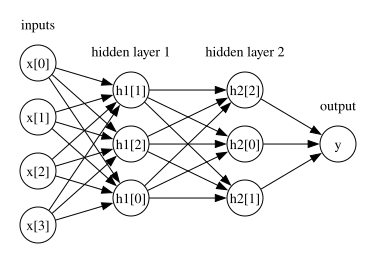

In [45]:
mglearn.plots.plot_two_hidden_layer_graph()

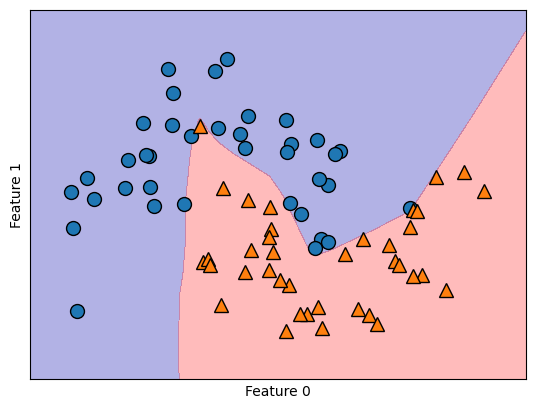

In [48]:
import matplotlib.pyplot as plt
import mglearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=42
)

mlp = MLPClassifier(solver="lbfgs", random_state=0).fit(X_train, y_train)
mglearn.plots.plot_2d_separator(mlp, X_train, fill=True, alpha=0.3)
mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.show()

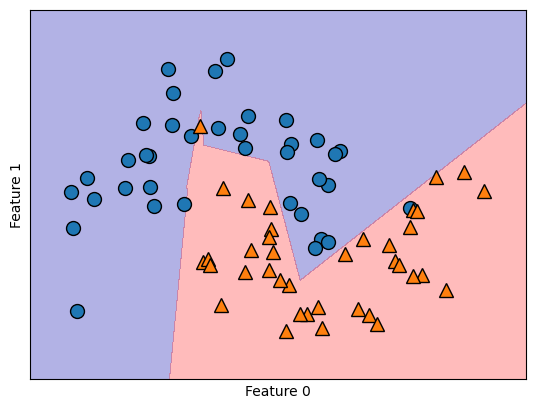

In [50]:
import matplotlib.pyplot as plt
import mglearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

# Setup data
X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=42
)

# Train MLP with 1 hidden layer containing 10 units
mlp = MLPClassifier(solver="lbfgs", random_state=0, hidden_layer_sizes=(10,))
mlp.fit(X_train, y_train)

# Plot decision boundary
mglearn.plots.plot_2d_separator(mlp, X_train, fill=True, alpha=0.3)
mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.show()

/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:602: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


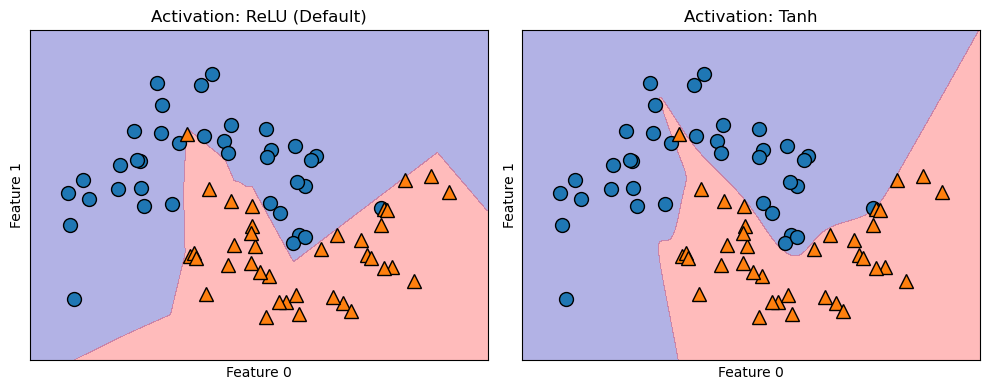

In [57]:
import matplotlib.pyplot as plt
import mglearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

# 1. Setup data
X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 2. Model 1: Default activation (relu)
mlp_relu = MLPClassifier(
    solver="lbfgs", random_state=0, hidden_layer_sizes=(10, 10)
)
mlp_relu.fit(X_train, y_train)
mglearn.plots.plot_2d_separator(mlp_relu, X_train, fill=True, alpha=0.3, ax=axes[0])
mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train, ax=axes[0])
axes[0].set_title("Activation: ReLU (Default)")
axes[0].set_xlabel("Feature 0")
axes[0].set_ylabel("Feature 1")

# 3. Model 2: Tanh activation
mlp_tanh = MLPClassifier(
    solver="lbfgs", activation="tanh", random_state=0, hidden_layer_sizes=(10, 10)
)
mlp_tanh.fit(X_train, y_train)
mglearn.plots.plot_2d_separator(mlp_tanh, X_train, fill=True, alpha=0.3, ax=axes[1])
mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train, ax=axes[1])
axes[1].set_title("Activation: Tanh")
axes[1].set_xlabel("Feature 0")
axes[1].set_ylabel("Feature 1")

plt.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:602: ConvergenceWarning: lbfgs failed to converge after 181 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:602: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:602: ConvergenceWarning: lbfgs failed to co

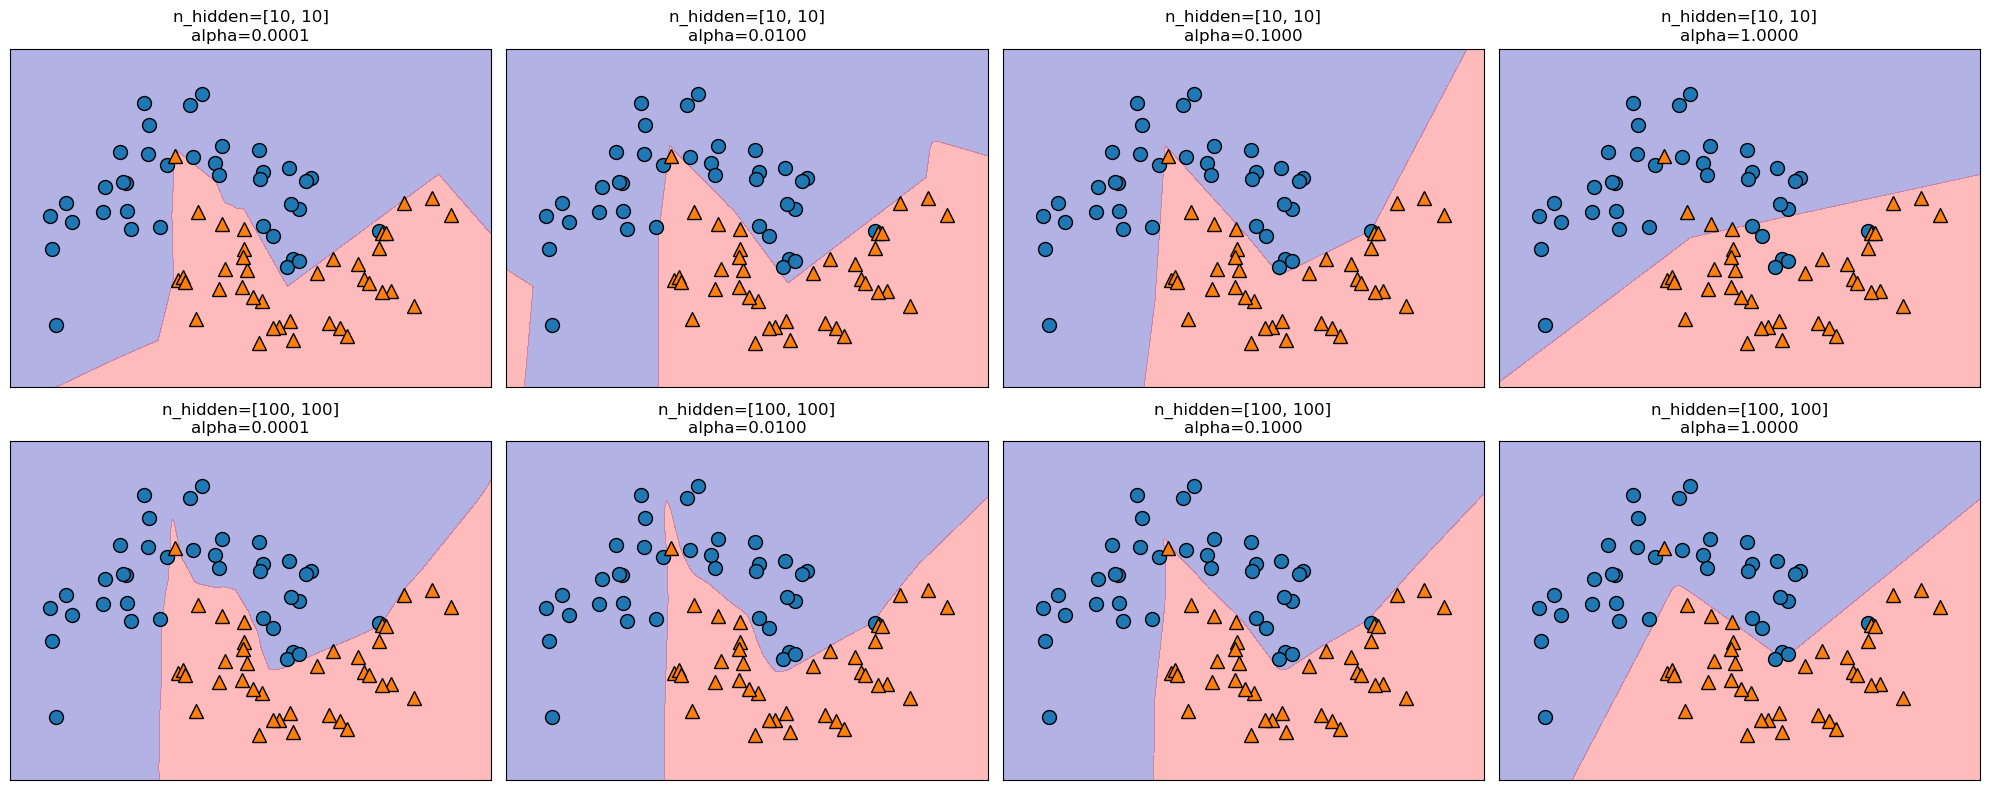

In [59]:
import matplotlib.pyplot as plt
import mglearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

# 1. Setup dataset
X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=42
)

# 2. Grid plot over layer sizes and L2 regularization (alpha)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for axx, n_hidden_nodes in zip(axes, [10, 100]):
    for ax, alpha in zip(axx, [0.0001, 0.01, 0.1, 1]):
        mlp = MLPClassifier(
            solver="lbfgs",
            random_state=0,
            hidden_layer_sizes=(n_hidden_nodes, n_hidden_nodes),
            alpha=alpha,
        )
        mlp.fit(X_train, y_train)

        mglearn.plots.plot_2d_separator(
            mlp, X_train, fill=True, alpha=0.3, ax=ax
        )
        mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train, ax=ax)
        ax.set_title(
            f"n_hidden=[{n_hidden_nodes}, {n_hidden_nodes}]\nalpha={alpha:.4f}"
        )

plt.tight_layout()
plt.show()

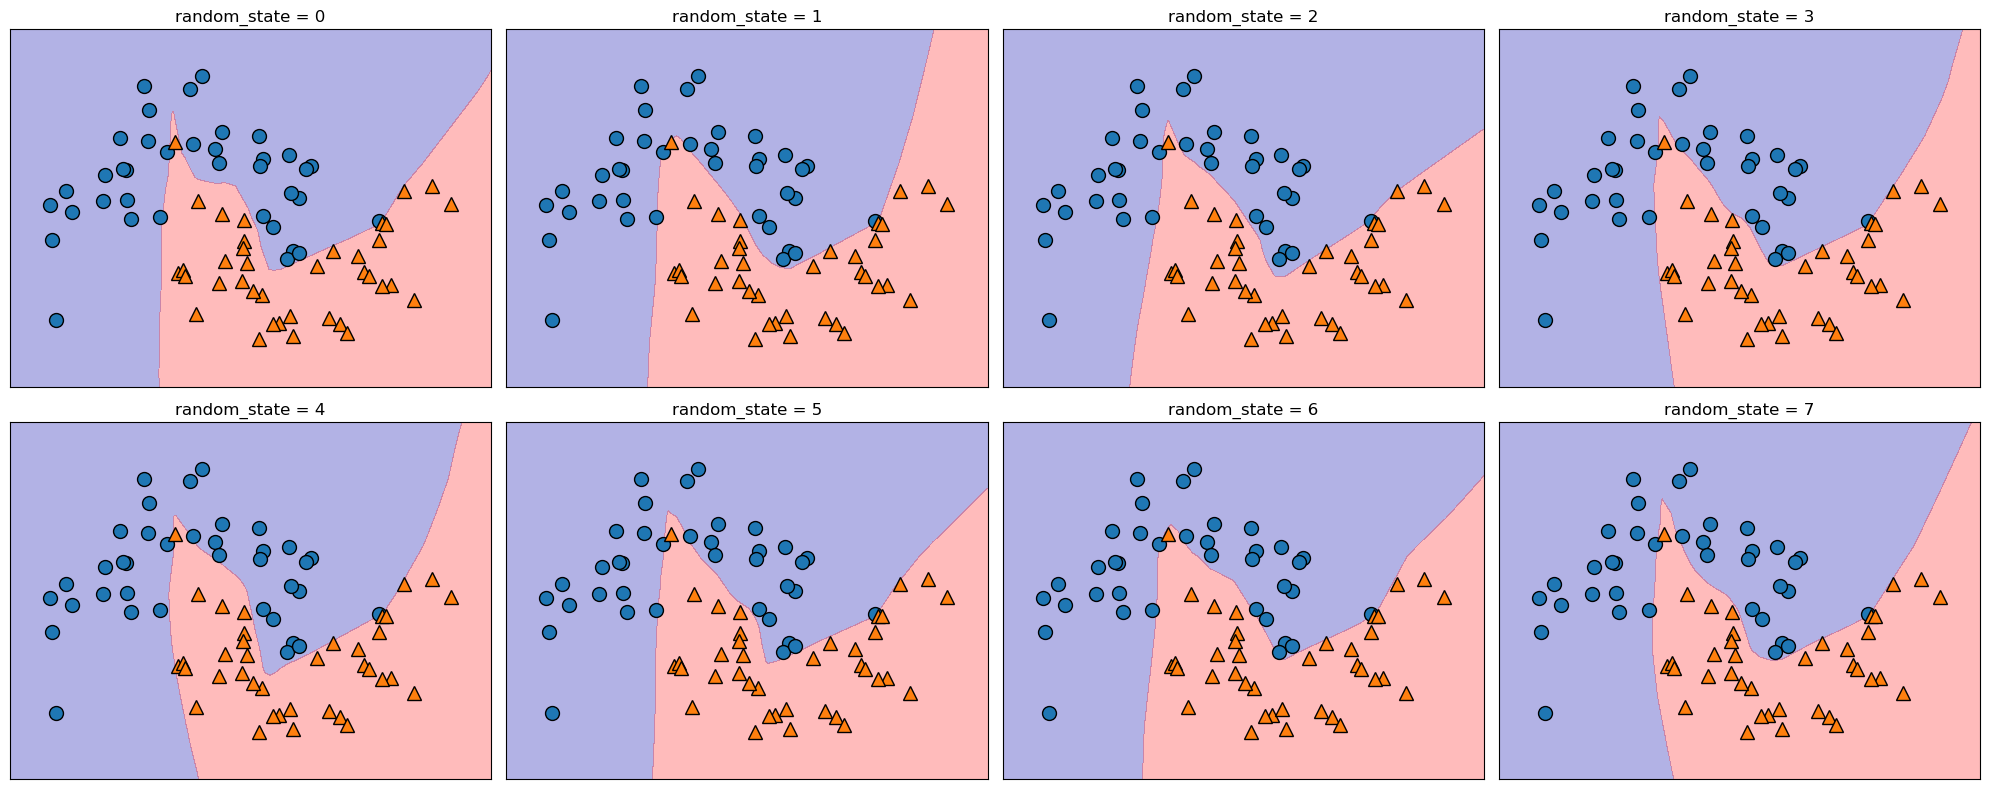

In [61]:
import matplotlib.pyplot as plt
import mglearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

# 1. Setup dataset
X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=42
)

# 2. Plot effect of different random initializations
fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for i, ax in enumerate(axes.ravel()):
    mlp = MLPClassifier(
        solver="lbfgs", random_state=i, hidden_layer_sizes=(100, 100)
    )
    mlp.fit(X_train, y_train)

    mglearn.plots.plot_2d_separator(mlp, X_train, fill=True, alpha=0.3, ax=ax)
    mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train, ax=ax)
    ax.set_title(f"random_state = {i}")

plt.tight_layout()
plt.show()

In [62]:
print("Cancer data per-feature maxima:\n{}".format(cancer.data.max(axis=0)))

Cancer data per-feature maxima:
[2.811e+01 3.928e+01 1.885e+02 2.501e+03 1.634e-01 3.454e-01 4.268e-01
 2.012e-01 3.040e-01 9.744e-02 2.873e+00 4.885e+00 2.198e+01 5.422e+02
 3.113e-02 1.354e-01 3.960e-01 5.279e-02 7.895e-02 2.984e-02 3.604e+01
 4.954e+01 2.512e+02 4.254e+03 2.226e-01 1.058e+00 1.252e+00 2.910e-01
 6.638e-01 2.075e-01]


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
cancer.data, cancer.target, random_state=0)
mlp = MLPClassifier(random_state=42)
mlp.fit(X_train, y_train)
print("Accuracy on training set: {:.2f}".format(mlp.score(X_train, y_train)))
print("Accuracy on test set: {:.2f}".format(mlp.score(X_test, y_test)))

Accuracy on training set: 0.94
Accuracy on test set: 0.92


In [64]:
# compute the mean value per feature on the training set
mean_on_train = X_train.mean(axis=0)
# compute the standard deviation of each feature on the training set
std_on_train = X_train.std(axis=0)
# subtract the mean, and scale by inverse standard deviation
# afterward, mean=0 and std=1
X_train_scaled = (X_train - mean_on_train) / std_on_train
# use THE SAME transformation (using training mean and std) on the test set
X_test_scaled = (X_test - mean_on_train) / std_on_train
mlp = MLPClassifier(random_state=0)
mlp.fit(X_train_scaled, y_train)
print("Accuracy on training set: {:.3f}".format(
mlp.score(X_train_scaled, y_train)))
print("Accuracy on test set: {:.3f}".format(mlp.score(X_test_scaled, y_test)))

Accuracy on training set: 0.991
Accuracy on test set: 0.965


/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [65]:
mlp = MLPClassifier(max_iter=1000, random_state=0)
mlp.fit(X_train_scaled, y_train)
print("Accuracy on training set: {:.3f}".format(
mlp.score(X_train_scaled, y_train)))
print("Accuracy on test set: {:.3f}".format(mlp.score(X_test_scaled, y_test)))

Accuracy on training set: 1.000
Accuracy on test set: 0.972


In [66]:
mlp = MLPClassifier(max_iter=1000, alpha=1, random_state=0)
mlp.fit(X_train_scaled, y_train)
print("Accuracy on training set: {:.3f}".format(
mlp.score(X_train_scaled, y_train)))
print("Accuracy on test set: {:.3f}".format(mlp.score(X_test_scaled, y_test)))

Accuracy on training set: 0.988
Accuracy on test set: 0.972


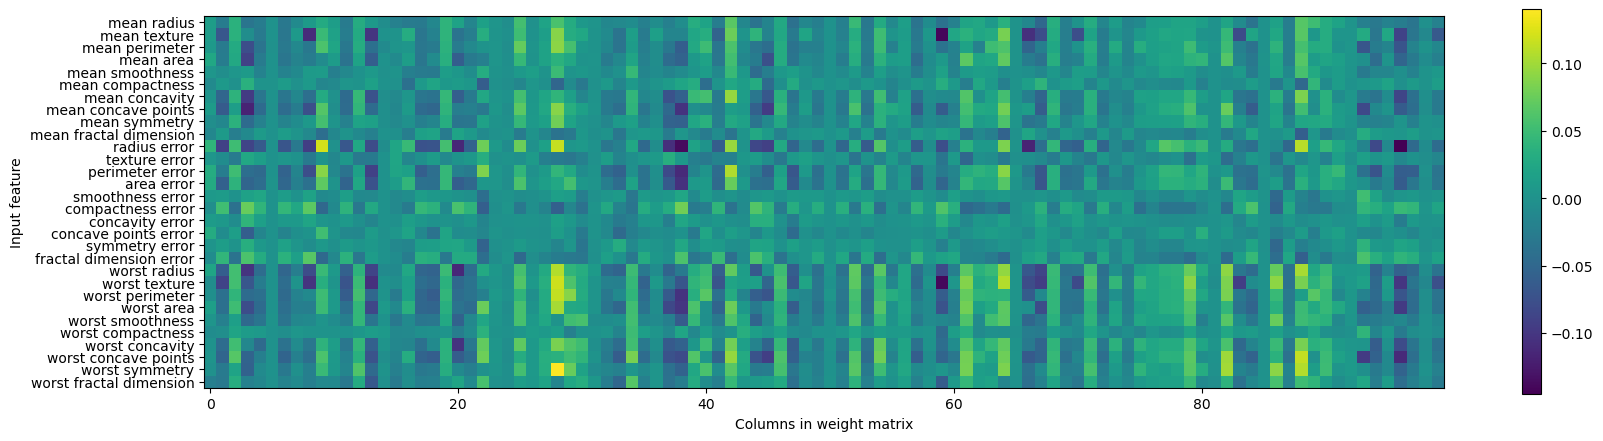

In [67]:
plt.figure(figsize=(20, 5))
plt.imshow(mlp.coefs_[0], interpolation='none', cmap='viridis')
plt.yticks(range(30), cancer.feature_names)
plt.xlabel("Columns in weight matrix")
plt.ylabel("Input feature")
plt.colorbar()

In [68]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.datasets import make_blobs, make_circles
X, y = make_circles(noise=0.25, factor=0.5, random_state=1)
# we rename the classes "blue" and "red" for illustration purposes
y_named = np.array(["blue", "red"])[y]
# we can call train_test_split with arbitrarily many arrays;
# all will be split in a consistent manner
X_train, X_test, y_train_named, y_test_named, y_train, y_test = \
train_test_split(X, y_named, y, random_state=0)
# build the gradient boosting model
gbrt = GradientBoostingClassifier(random_state=0)
gbrt.fit(X_train, y_train_named)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [69]:
print("X_test.shape: {}".format(X_test.shape))
print("Decision function shape: {}".format(
gbrt.decision_function(X_test).shape))

X_test.shape: (25, 2)
Decision function shape: (25,)


In [70]:
# show the first few entries of decision_function
print("Decision function:\n{}".format(gbrt.decision_function(X_test)[:6]))

Decision function:
[ 4.13592603 -1.70169917 -3.95106099 -3.62609552  4.28986642  3.66166081]


In [71]:
print("Thresholded decision function:\n{}".format(
gbrt.decision_function(X_test) > 0))
print("Predictions:\n{}".format(gbrt.predict(X_test)))

Thresholded decision function:
[ True False False False  True  True False  True  True  True False  True
  True False  True False False False  True  True  True  True  True False
 False]
Predictions:
['red' 'blue' 'blue' 'blue' 'red' 'red' 'blue' 'red' 'red' 'red' 'blue'
 'red' 'red' 'blue' 'red' 'blue' 'blue' 'blue' 'red' 'red' 'red' 'red'
 'red' 'blue' 'blue']


In [72]:
# make the boolean True/False into 0 and 1
greater_zero = (gbrt.decision_function(X_test) > 0).astype(int)
# use 0 and 1 as indices into classes_
pred = gbrt.classes_[greater_zero]
# pred is the same as the output of gbrt.predict
print("pred is equal to predictions: {}".format(
np.all(pred == gbrt.predict(X_test))))

pred is equal to predictions: True


In [73]:
decision_function = gbrt.decision_function(X_test)
print("Decision function minimum: {:.2f} maximum: {:.2f}".format(
np.min(decision_function), np.max(decision_function)))

Decision function minimum: -7.69 maximum: 4.29


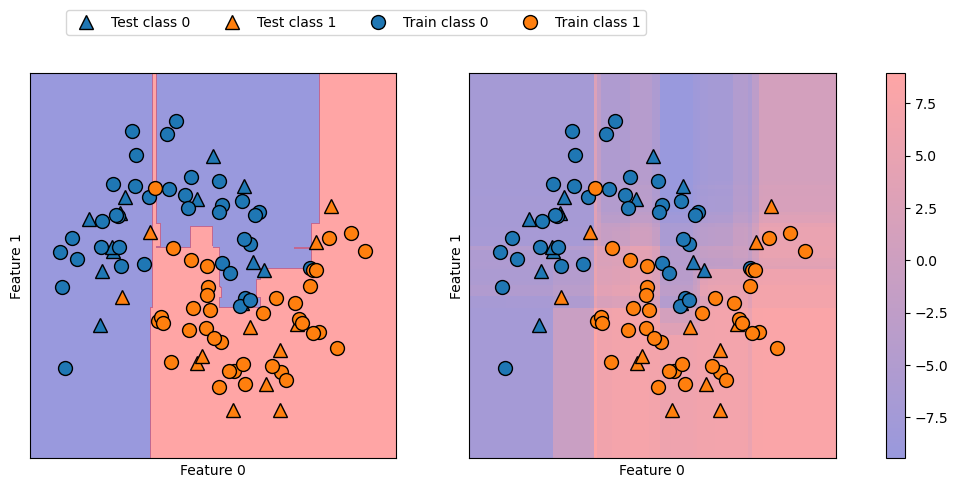

In [75]:
import matplotlib.pyplot as plt
import mglearn
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# 1. Setup data and fit GradientBoostingClassifier
X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=42
)

gbrt = GradientBoostingClassifier(random_state=0)
gbrt.fit(X_train, y_train)

# 2. Plot decision boundary and continuous decision scores
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

mglearn.tools.plot_2d_separator(
    gbrt, X, ax=axes[0], alpha=0.4, fill=True, cm=mglearn.cm2
)
scores_image = mglearn.tools.plot_2d_scores(
    gbrt, X, ax=axes[1], alpha=0.4, cm=mglearn.ReBl
)

for ax in axes:
    # Plot training and test points
    mglearn.discrete_scatter(
        X_test[:, 0], X_test[:, 1], y_test, markers="^", ax=ax
    )
    mglearn.discrete_scatter(
        X_train[:, 0], X_train[:, 1], y_train, markers="o", ax=ax
    )
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")

cbar = plt.colorbar(scores_image, ax=axes.tolist())
axes[0].legend(
    ["Test class 0", "Test class 1", "Train class 0", "Train class 1"],
    ncol=4,
    loc=(0.1, 1.1),
)

plt.show()

In [76]:
print("Shape of probabilities: {}".format(gbrt.predict_proba(X_test).shape))

Shape of probabilities: (25, 2)


In [77]:
# show the first few entries of predict_proba
print("Predicted probabilities:\n{}".format(
gbrt.predict_proba(X_test[:6])))

Predicted probabilities:
[[0.00118477 0.99881523]
 [0.00131864 0.99868136]
 [0.0011826  0.9988174 ]
 [0.98889844 0.01110156]
 [0.23527335 0.76472665]
 [0.97925065 0.02074935]]


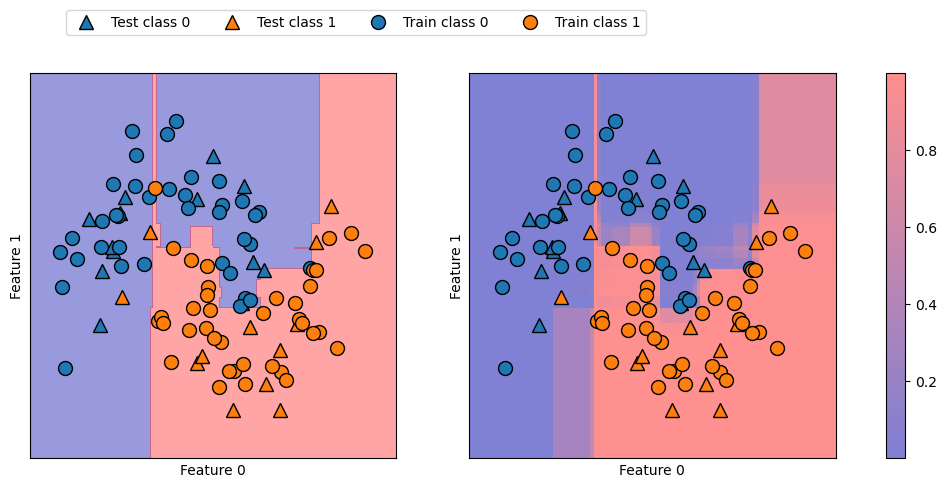

In [79]:
import matplotlib.pyplot as plt
import mglearn
from sklearn.datasets import make_moons
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split

# 1. Prepare dataset and fit model
X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=42
)

gbrt = GradientBoostingClassifier(random_state=0)
gbrt.fit(X_train, y_train)

# 2. Plot hard boundaries vs predicted probabilities
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

mglearn.tools.plot_2d_separator(
    gbrt, X, ax=axes[0], alpha=0.4, fill=True, cm=mglearn.cm2
)
scores_image = mglearn.tools.plot_2d_scores(
    gbrt, X, ax=axes[1], alpha=0.5, cm=mglearn.ReBl, function="predict_proba"
)

for ax in axes:
    # plot training and test points
    mglearn.discrete_scatter(
        X_test[:, 0], X_test[:, 1], y_test, markers="^", ax=ax
    )
    mglearn.discrete_scatter(
        X_train[:, 0], X_train[:, 1], y_train, markers="o", ax=ax
    )
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")

cbar = plt.colorbar(scores_image, ax=axes.tolist())
axes[0].legend(
    ["Test class 0", "Test class 1", "Train class 0", "Train class 1"],
    ncol=4,
    loc=(0.1, 1.1),
)

plt.show()

In [81]:
from sklearn.datasets import load_iris
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
iris.data, iris.target, random_state=42)
gbrt = GradientBoostingClassifier(learning_rate=0.01, random_state=0)
gbrt.fit(X_train, y_train)
print("Decision function shape: {}".format(gbrt.decision_function(X_test).shape))
# plot the first few entries of the decision function
print("Decision function:\n{}".format(gbrt.decision_function(X_test)[:6, :]))

Decision function shape: (38, 3)
Decision function:
[[-0.89604809  1.14724958 -0.82754003]
 [ 1.16113086 -0.80789044 -0.82827067]
 [-0.89091511 -0.77671169  1.19653416]
 [-0.89604809  1.14724958 -0.82754003]
 [-0.89763468  0.96497584 -0.10374792]
 [ 1.16113086 -0.80789044 -0.82827067]]


In [82]:
print("Argmax of decision function:\n{}".format(
np.argmax(gbrt.decision_function(X_test), axis=1)))
print("Predictions:\n{}".format(gbrt.predict(X_test)))

Argmax of decision function:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0]
Predictions:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0]


In [83]:
# show the first few entries of predict_proba
print("Predicted probabilities:\n{}".format(gbrt.predict_proba(X_test)[:6]))
# show that sums across rows are one
print("Sums: {}".format(gbrt.predict_proba(X_test)[:6].sum(axis=1)))

Predicted probabilities:
[[0.10217718 0.78840034 0.10942248]
 [0.78347147 0.10936745 0.10716108]
 [0.09818072 0.11005864 0.79176065]
 [0.10217718 0.78840034 0.10942248]
 [0.10360005 0.66723901 0.22916094]
 [0.78347147 0.10936745 0.10716108]]
Sums: [1. 1. 1. 1. 1. 1.]


In [84]:
print("Argmax of predicted probabilities:\n{}".format(
np.argmax(gbrt.predict_proba(X_test), axis=1)))
print("Predictions:\n{}".format(gbrt.predict(X_test)))

Argmax of predicted probabilities:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0]
Predictions:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0]


In [86]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# 1. Load data and split
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, random_state=0
)

# 2. Represent targets by their string class names
named_target = iris.target_names[y_train]

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, named_target)

# 3. Print predictions and decision function mapping
print("unique classes in training data: {}".format(logreg.classes_))
print("predictions: {}".format(logreg.predict(X_test)[:10]))

argmax_dec_func = np.argmax(logreg.decision_function(X_test), axis=1)
print("argmax of decision function: {}".format(argmax_dec_func[:10]))
print(
    "argmax combined with classes_: {}".format(
        logreg.classes_[argmax_dec_func][:10]
    )
)

unique classes in training data: ['setosa' 'versicolor' 'virginica']
predictions: ['virginica' 'versicolor' 'setosa' 'virginica' 'setosa' 'virginica'
 'setosa' 'versicolor' 'versicolor' 'versicolor']
argmax of decision function: [2 1 0 2 0 2 0 1 1 1]
argmax combined with classes_: ['virginica' 'versicolor' 'setosa' 'virginica' 'setosa' 'virginica'
 'setosa' 'versicolor' 'versicolor' 'versicolor']
